C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.3068 - loss: 1.9402 - val_accuracy: 0.3607 - val_loss: 1.8041
Epoch 2/15
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.3646 - loss: 1.7869 - val_accuracy: 0.3733 - val_loss: 1.7671
Epoch 3/15
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 19s 9ms/step - accuracy: 0.3886 - loss: 1.7253 - val_accuracy: 0.3925 - val_loss: 1.6983
Epoch 4/15
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.4033 - loss: 1.6795 - val_accuracy: 0.4002 - val_loss: 1.6916
Epoch 5/15
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.4120 - loss: 1.6550 - val_accuracy: 0.4090 - val_loss: 1.6500
Epoch 6/15
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.4188 - loss: 1.6322 - val_accuracy: 0.4103 - val_loss: 1.6656
Epoch 7/15
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 19s 9ms/step - accuracy: 0.4231 - loss: 1.6175 - val_accuracy: 0.4265 - val_loss: 1.6323
Epoch 8/15
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.4256 - lo

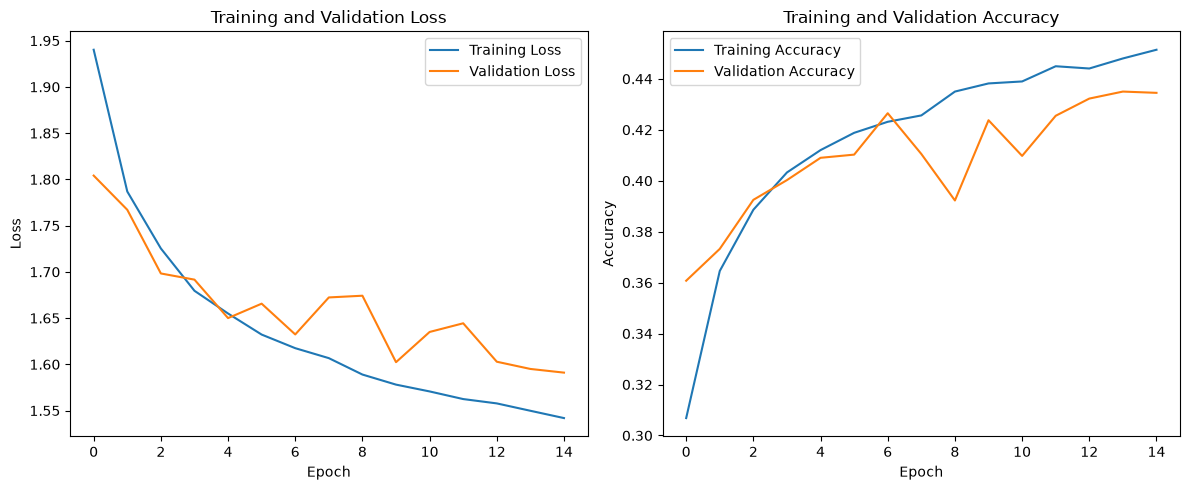

In [2]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

# 2. Load dataset
data = pd.read_csv(r"D:\DL\LP IV Updated Datasets\FNN and CNN\CIFAR10\cifar-10.csv")

# 3. Clean missing values
data = data.dropna(subset=['label'])
data[data.columns.drop('label')] = data[data.columns.drop('label')].fillna(0)

# 4. Split features and labels
X = data.drop('label', axis=1).values.astype('float32') / 255.0
y = data['label'].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Define FNN model
model = Sequential([
    Flatten(input_shape=(3072,)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# 6. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 7. Train model
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1
)

# 8. Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# 9. Plot loss and accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()